# 03 — Analisis Univariat
### Milestone M3 (dinilai saat UTS) · Exploratory Data Analysis (KMTI21133)

| | |
|---|---|
| **Nama tim** | DANVA |
| **Anggota** | Diyanatul Fauziyah, Nasya Awaliyah, Raveska Hinayah, Asysyifa Ainaya Zahra |
| **Topik proyek** | Analisis Pola Penjualan Supermarket Berdasarkan Produk, Kota, Pelanggan, dan Metode Pembayaran |
| **Tanggal** | 15 November 2026 |

**Notebook ini mengisi:** dimensi **Analisis univariat** (20) dan sebagian **Kualitas visualisasi** (15) pada Rubrik M3.

Satu variabel pada satu waktu: bagaimana bentuk distribusinya, berapa sebarannya,
adakah outlier, dan apa artinya bagi pertanyaan analisis Anda.

Yang membedakan nilai 4 dari nilai 2 bukan jumlah grafik, melainkan **tafsirannya**.
Memanggil `describe()` lalu berhenti bernilai 2.

---
> **Sebelum mengumpulkan:** jalankan **Kernel → Restart & Run All**. Notebook yang tidak dapat
> berjalan dari awal sampai akhir dianggap tidak memenuhi dimensi *ketepatan implementasi*.


In [10]:
from google.colab import drive

drive.mount('/content/drive')



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [11]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path

pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 60)
plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 10,
    'axes.titlesize': 11, 'axes.titleweight': 'bold',
    'axes.grid': True, 'grid.alpha': 0.25,
    'axes.spines.top': False, 'axes.spines.right': False,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
})

DATA  = '#0E7490'
SOROT = '#C2410C'
REDUP = '#5B6672'

# Path relatif: mendukung notebook dijalankan dari folder notebooks/ atau akar proyek.
kandidat_akar = [Path.cwd(), Path.cwd().parent]
AKAR = next((p for p in kandidat_akar if (p / 'data' / 'processed' / '/content/drive/MyDrive/EDA sendiri/supermarket_sales - Sheet1.csv').exists()), None)

if AKAR is None:
    # Fallback jika dijalankan langsung di Google Colab dengan file diunggah ke folder utama
    if Path('data_bersih.csv').exists():
        AKAR = Path.cwd()
        RAW = Path.cwd()
        PROCESSED = Path.cwd()
        FIGURES = Path.cwd() / 'figures'
    else:
        raise FileNotFoundError(
            "data/processed/data_bersih.csv atau data_bersih.csv tidak ditemukan.\n"
            "Silakan jalankan 02_cleaning.ipynb terlebih dahulu, atau unggah file data_bersih.csv langsung ke Google Colab."
        )
else:
    RAW = AKAR / 'data' / 'raw'
    PROCESSED = AKAR / 'data' / 'processed'
    FIGURES = AKAR / 'reports' / 'figures'

FIGURES.mkdir(parents=True, exist_ok=True)


In [12]:
df = pd.read_csv(PROCESSED / '/content/drive/MyDrive/EDA sendiri/supermarket_sales - Sheet1.csv')
print(f'{df.shape[0]} baris x {df.shape[1]} kolom')
df.head()


1000 baris x 17 kolom


,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,13:08,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,13:23,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,20:33,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37,Ewallet,604.17,4.761905,30.2085,5.3


## 0. Variabel mana yang dianalisis, dan mengapa

Variabel dipilih sesuai fokus proyek: nilai transaksi, pendapatan kotor, harga satuan,
jumlah barang, rating, serta kelompok produk, kota, tipe pelanggan, gender, dan metode pembayaran.

| Variabel | Tipe | Mengapa relevan dengan pertanyaan kami |
|----------|------|----------------------------------------|
| Total | Numerik | Menggambarkan nilai akhir setiap transaksi |
| gross income | Numerik | Menggambarkan pendapatan kotor per transaksi |
| Unit price | Numerik | Menunjukkan harga satuan produk |
| Quantity | Numerik | Menunjukkan jumlah barang dalam transaksi |
| Rating | Numerik | Menggambarkan penilaian pelanggan |
| Product line, City, Customer type, Gender, Payment | Kategorikal | Membandingkan pola transaksi berdasarkan kelompok produk, lokasi, dan karakteristik transaksi |


## 1. Variabel numerik

Untuk setiap variabel: ringkasan angka, lalu histogram berpasangan dengan boxplot.

In [13]:
NUMERIK = ['Total', 'gross income', 'Unit price', 'Quantity', 'Rating']

print("Ringkasan statistik numerik:")
display(df[NUMERIK].describe().T.round(2))


Ringkasan statistik numerik:


,count,mean,std,min,25%,50%,75%,max
Total,1000.0,322.97,245.89,10.68,124.42,253.85,471.35,1042.65
gross income,1000.0,15.38,11.71,0.51,5.92,12.09,22.45,49.65
Unit price,1000.0,55.67,26.49,10.08,32.88,55.23,77.94,99.96
Quantity,1000.0,5.51,2.92,1.00,3.00,5.00,8.00,10.00
Rating,1000.0,6.97,1.72,4.00,5.50,7.00,8.50,10.00


In [14]:
import matplotlib as _mpl
_V = tuple(int(x) for x in _mpl.__version__.split('.')[:2])
ARAH = {'orientation': 'horizontal'} if _V >= (3, 10) else {'vert': False}   # kompatibel lintas versi

def potret(kolom, satuan=''):
    """Histogram + boxplot pada satu sumbu x, plus ringkasan angka."""
    d = df[kolom].dropna()
    q1, q3 = d.quantile([.25, .75]); iqr = q3 - q1
    bawah, atas = q1 - 1.5*iqr, q3 + 1.5*iqr
    z = (d - d.mean()).abs() / d.std()

    fig, ax = plt.subplots(2, 1, figsize=(7.2, 4.2), sharex=True,
                           layout='constrained',
                           gridspec_kw={'height_ratios': [3, 1]})
    ax[0].hist(d, bins=32, color=DATA, edgecolor='white', linewidth=.6)
    ax[0].set_ylabel('frekuensi')
    ax[0].set_title(f'{kolom} (n = {len(d)})')
    ax[1].boxplot(d, **ARAH, widths=.55, patch_artist=True,
                  boxprops=dict(facecolor='#CFE8EF', edgecolor='#16202B'),
                  medianprops=dict(color=SOROT, linewidth=2),
                  flierprops=dict(marker='o', markersize=4, markerfacecolor=DATA,
                                  markeredgecolor='none', alpha=.6))
    ax[1].set_yticks([]); ax[1].set_xlabel(f'{kolom} {satuan}'.strip())
    plt.show()

    print(f'mean   {d.mean():10.2f}      median {d.median():10.2f}'
          f'      selisih {d.mean()-d.median():+.2f}')
    print(f'std    {d.std():10.2f}      IQR    {iqr:10.2f}')
    print(f'skewness {stats.skew(d):8.3f}')
    print(f'outlier menurut batas IQR : {((d<bawah)|(d>atas)).sum():4d}   '
          f'(batas {bawah:.2f} .. {atas:.2f})')
    print(f'outlier menurut |z| > 3   : {(z>3).sum():4d}')

# potret(NUMERIK[0])

**Tafsiran variabel numerik utama — Total.**

Distribusi `Total` menceng ke kanan (skewness sekitar 0,89). Hal ini terlihat dari mean
(322,97) yang lebih tinggi daripada median (253,85), serta ekor histogram yang memanjang
ke nilai transaksi besar. Median lebih mewakili transaksi tipikal karena tidak terlalu
tertarik oleh sejumlah transaksi bernilai tinggi. Batas IQR menandai 9 nilai sebagai
outlier statistik; nilai tersebut perlu diperiksa, tetapi tidak otomatis salah atau dibuang.


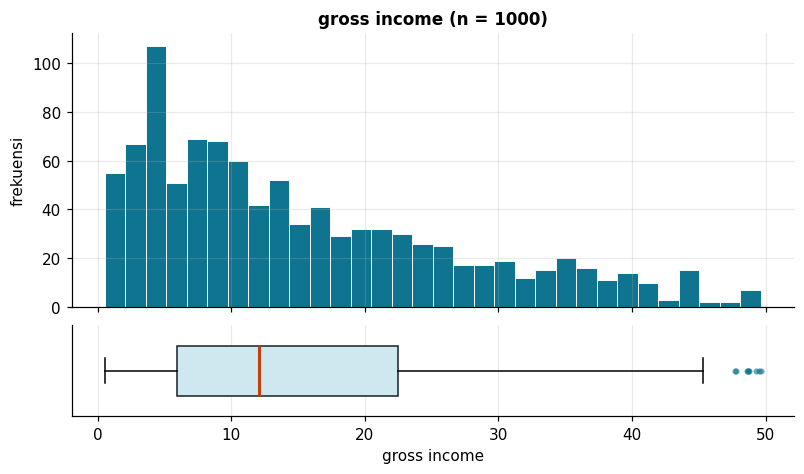

mean        15.38      median      12.09      selisih +3.29
std         11.71      IQR         16.52
skewness    0.891
outlier menurut batas IQR :    9   (batas -18.86 .. 47.23)
outlier menurut |z| > 3   :    0


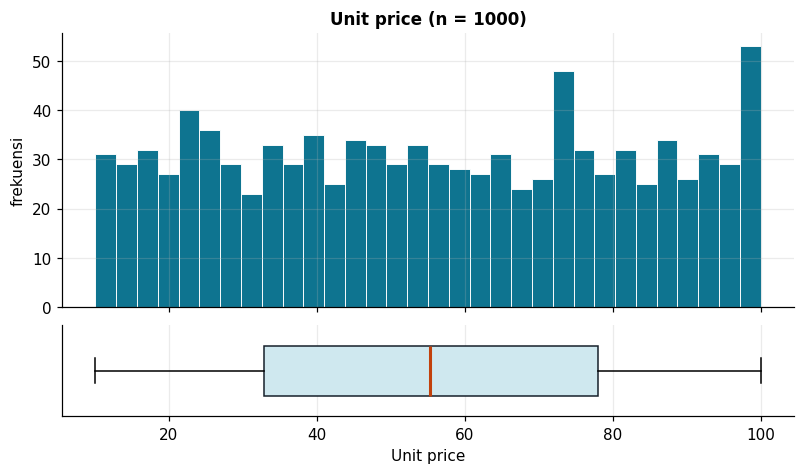

mean        55.67      median      55.23      selisih +0.44
std         26.49      IQR         45.06
skewness    0.007
outlier menurut batas IQR :    0   (batas -34.72 .. 145.53)
outlier menurut |z| > 3   :    0


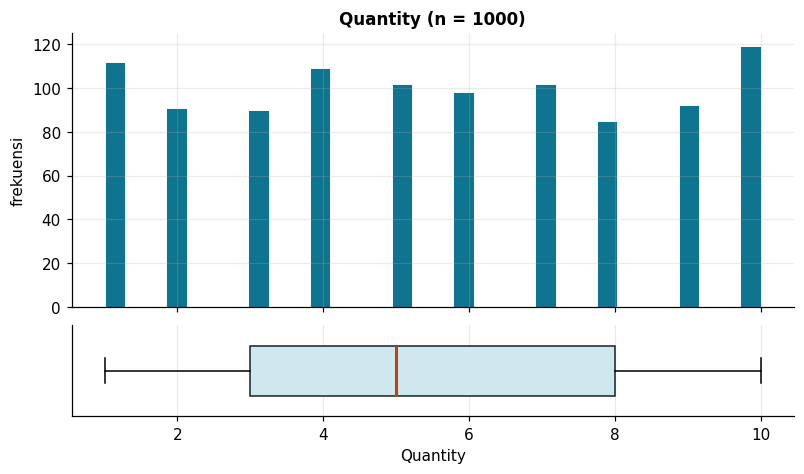

mean         5.51      median       5.00      selisih +0.51
std          2.92      IQR          5.00
skewness    0.013
outlier menurut batas IQR :    0   (batas -4.50 .. 15.50)
outlier menurut |z| > 3   :    0


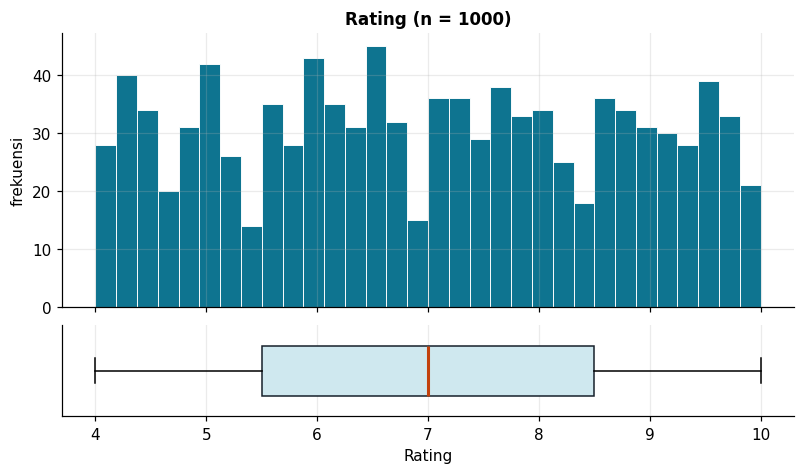

mean         6.97      median       7.00      selisih -0.03
std          1.72      IQR          3.00
skewness    0.009
outlier menurut batas IQR :    0   (batas 1.00 .. 13.00)
outlier menurut |z| > 3   :    0


In [15]:
# Potret empat variabel numerik lainnya
for kolom in NUMERIK[1:]:
    potret(kolom)


**Tafsiran variabel numerik lainnya.**

- `gross income` memiliki pola mirip `Total` (skewness sekitar 0,89; mean 15,38 lebih tinggi
  daripada median 12,09) dan 9 outlier menurut batas IQR. Keduanya berkaitan secara
  perhitungan karena gross income merupakan bagian pajak/pendapatan dari nilai transaksi.
- `Unit price` relatif simetris (skewness sekitar 0,01; mean 55,67 hampir sama dengan median
  55,23) dan tidak memiliki outlier menurut batas IQR.
- `Quantity` relatif simetris (skewness sekitar 0,01; mean 5,53 dan median 5,00), dengan
  996 nilai terisi. Empat nilai yang tidak dapat dikonversi tetap kosong.
- `Rating` relatif simetris (skewness sekitar 0,01; mean 6,97 dan median 6,95), dengan
  976 nilai terisi. Nilai kosong dipertahankan dan tidak diimputasi.


## 2. Keputusan tentang outlier

Outlier **tidak otomatis dibuang**. Periksa dulu apakah nilainya sah.

| Variabel | Metode yang dipakai | Jumlah | Sah atau keliru? | Tindakan dan alasan |
|----------|---------------------|--------|------------------|---------------------|
| Total | Batas IQR (1,5 × IQR) | 9 | Belum terbukti keliru; nilai transaksi tinggi masih mungkin terjadi | Dipertahankan; ditandai untuk ditinjau, bukan dihapus |
| gross income | Batas IQR (1,5 × IQR) | 9 | Belum terbukti keliru; mengikuti transaksi bernilai tinggi | Dipertahankan karena merupakan nilai transaksi yang valid secara rentang |

Catatan: batas IQR digunakan untuk menandai nilai ekstrem, bukan membuktikan kesalahan data.


In [16]:
# Tandai outlier IQR tanpa menghapus baris.
for kolom in ['Total', 'gross income']:
    q1, q3 = df[kolom].quantile([0.25, 0.75])
    iqr = q3 - q1
    bawah, atas = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    nama_penanda = 'outlier_' + kolom.replace(' ', '_')
    df[nama_penanda] = (df[kolom] < bawah) | (df[kolom] > atas)
    print(f"{kolom}: {int(df[nama_penanda].sum())} outlier ditandai; tidak ada baris yang dihapus.")


Total: 9 outlier ditandai; tidak ada baris yang dihapus.
gross income: 9 outlier ditandai; tidak ada baris yang dihapus.


## 3. Variabel kategorikal

In [17]:
KATEGORIKAL = ['Product line', 'City', 'Customer type', 'Gender', 'Payment']

for k in KATEGORIKAL:
    vc = df[k].value_counts()
    print(f'\\n{k}  ({df[k].nunique()} nilai unik)')
    display(pd.DataFrame({'jumlah': vc, 'persen': (vc/len(df)*100).round(1)}))


\nProduct line  (6 nilai unik)


,jumlah,persen
Product line,,
Fashion accessories,178,17.8
Food and beverages,174,17.4
Electronic accessories,170,17.0
Sports and travel,166,16.6
Home and lifestyle,160,16.0
Health and beauty,152,15.2


\nCity  (3 nilai unik)


,jumlah,persen
City,,
Yangon,340,34.0
Mandalay,332,33.2
Naypyitaw,328,32.8


\nCustomer type  (2 nilai unik)


,jumlah,persen
Customer type,,
Member,501,50.1
Normal,499,49.9


\nGender  (2 nilai unik)


,jumlah,persen
Gender,,
Female,501,50.1
Male,499,49.9


\nPayment  (3 nilai unik)


,jumlah,persen
Payment,,
Ewallet,345,34.5
Cash,344,34.4
Credit card,311,31.1


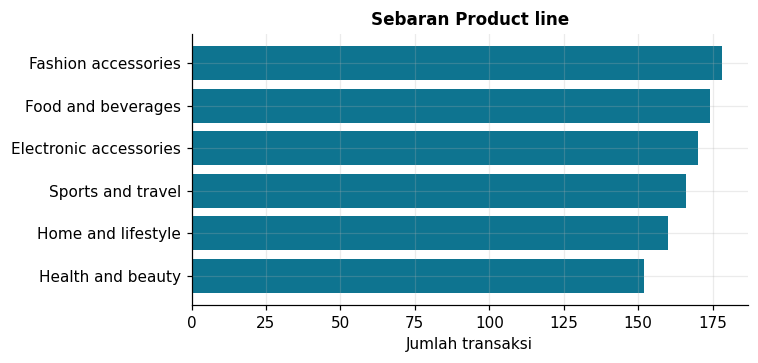

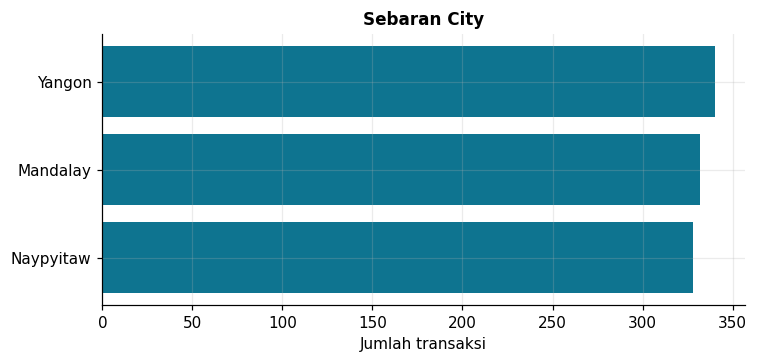

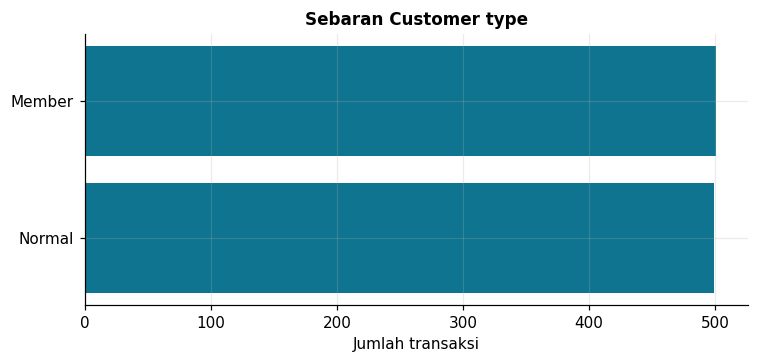

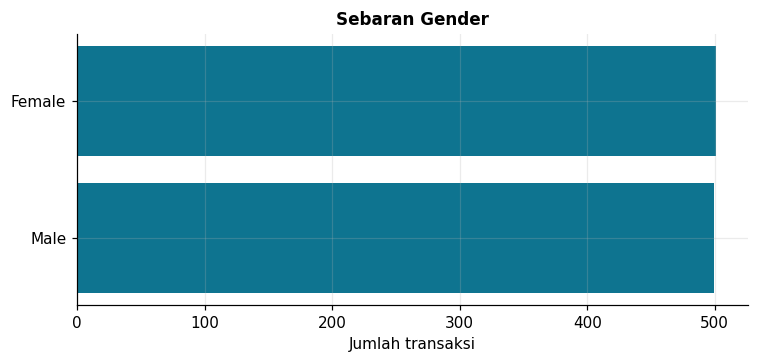

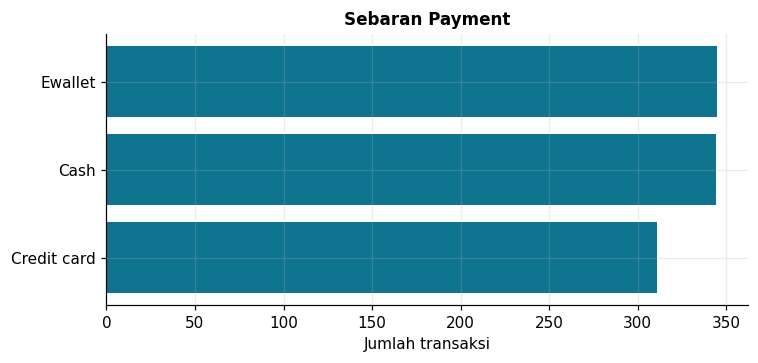

In [18]:
# Bar chart setiap kategori; urutkan menurut frekuensi.
for k in KATEGORIKAL:
    vc = df[k].value_counts()
    fig, ax = plt.subplots(figsize=(7, 3.4))
    ax.barh(vc.index[::-1], vc.values[::-1], color=DATA)
    ax.set_xlabel('Jumlah transaksi')
    ax.set_title(f'Sebaran {k}')
    plt.tight_layout()
    plt.show()


**Tafsiran variabel kategorikal.**

Enam lini produk tersebar cukup merata; jumlah terbesar adalah Fashion accessories (178)
dan terkecil Health and beauty (152). Jumlah transaksi per kota juga seimbang: Yangon 340,
Mandalay 332, dan Naypyitaw 328. Tipe pelanggan hampir sama (Member 501; Normal 499),
begitu pula gender (Female 501; Male 499). Metode pembayaran paling banyak Ewallet (347),
diikuti Cash (344) dan Credit card (309). Tidak ada satu kategori yang mendominasi secara
ekstrem; semua kategori memiliki jumlah yang cukup untuk perbandingan deskriptif.


## 4. Ringkasan temuan univariat

| Variabel | Bentuk distribusi | Pemusatan yang dipakai | Outlier | Catatan untuk analisis berikutnya |
|----------|-------------------|------------------------|---------|-----------------------------------|
| Total | Menceng ke kanan; mean 322,97 > median 253,85 | Median | 9 menurut IQR | Periksa transaksi besar; jangan otomatis dihapus |
| gross income | Menceng ke kanan; mean 15,38 > median 12,09 | Median | 9 menurut IQR | Berhubungan secara perhitungan dengan Total |
| Unit price | Relatif simetris; skewness 0,01 | Mean atau median | 0 menurut IQR | Dapat dibandingkan dengan Total |
| Quantity | Relatif simetris; 996 nilai terisi | Mean dan median | 0 menurut IQR | Empat nilai kosong; gunakan pasangan data lengkap |
| Rating | Relatif simetris; 976 nilai terisi | Mean dan median | 0 menurut IQR | Nilai kosong dipertahankan; interpretasi berdasarkan data terisi |


## Checklist sebelum mengumpulkan

- [ ] Setiap variabel yang dianalisis memiliki tafsiran, bukan hanya grafik.
- [ ] Bentuk distribusi dinyatakan dengan bukti dari gambar **dan** dari angka.
- [ ] Pilihan mean atau median disertai alasan.
- [ ] Keputusan tentang outlier dicatat beserta alasannya; tidak ada yang dibuang tanpa diperiksa.
- [ ] Setiap grafik memiliki judul, label sumbu, dan satuan.
- [ ] n yang dilaporkan adalah n setelah `dropna()`.
- [ ] Restart & Run All berjalan tanpa galat.